# MLIP
Short, independent practice codes on the building blocks of machine-learned interatomic potentials.

| # | Exercise | Key idea |
|---|---|---|
| 1 | Dimer energy and force, finite-difference check | $\mathbf F=-\nabla E$ |
| 2 | Cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ | descriptor as a smooth RDF |
| 4 | Angular function $G^4$ versus bond angle | angular resolution, $\lambda$ and $\zeta$ |

Units are Lennard-Jones reduced units ($\epsilon=\sigma=1$). Only NumPy and Matplotlib are needed.

---
## Exercise 1. Dimer energy and force
$U(r)=4\left[r^{-12}-r^{-6}\right]$, force on atom 2 along the bond $F=-dU/dr$. Check the analytic force against the central difference $-[U(r+h)-U(r-h)]/2h$.

In [1]:
import numpy as np

U  = lambda r: 4 * (r**-12 - r**-6)
dU = lambda r: 4 * (-12 * r**-13 + 6 * r**-7)

h = 1e-5
for r in (0.95, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("minimum at r_m = 2^(1/6) =", round(2**(1/6), 4), " U(r_m) =", round(U(2**(1/6)), 4))

r = 0.95  U =  +1.9610  F =  +59.1376  |diff| = 2.8e-07
r = 1.12  U =  -0.9998  F =   +0.1440  |diff| = 1.9e-08
r = 1.50  U =  -0.3203  F =   -1.1580  |diff| = 2.6e-10
r = 2.00  U =  -0.0615  F =   -0.1816  |diff| = 4.0e-11
minimum at r_m = 2^(1/6) = 1.1225  U(r_m) = -1.0


In [2]:
import numpy as np

D_e = 1.0
a = 2.0
r_e = 2**(1/6)

U  = lambda r: D_e * (1 - np.exp(-a * (r - r_e)))**2
dU = lambda r: 2 * D_e * a * np.exp(-a * (r - r_e)) * (1 - np.exp(-a * (r - r_e)))

h = 1e-5
for r in (0.95, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("Minimum at r_e =", r_e, " U(r_e) =", U(r_e))

r = 0.95  U =  +0.1696  F =   +2.3261  |diff| = 1.7e-09
r = 1.12  U =  +0.0000  F =   +0.0198  |diff| = 8.1e-10
r = 1.50  U =  +0.2809  F =   -0.9964  |diff| = 1.1e-10
r = 2.00  U =  +0.6841  F =   -0.5720  |diff| = 1.9e-11
Minimum at r_e = 1.122462048309373  U(r_e) = 0.0


**Your turn.** Replace the potential by a Morse potential $U=(1-e^{-2(r-1)})^2-1$ and its derivative. Where is the force zero?

---
## Exercise 2. Cutoff functions
A hard cutoff makes the energy jump when an atom crosses $r_c$. Compare a hard step, the cosine cutoff and the polynomial envelope ($p=6$) by plotting $f$ and $df/dr$.

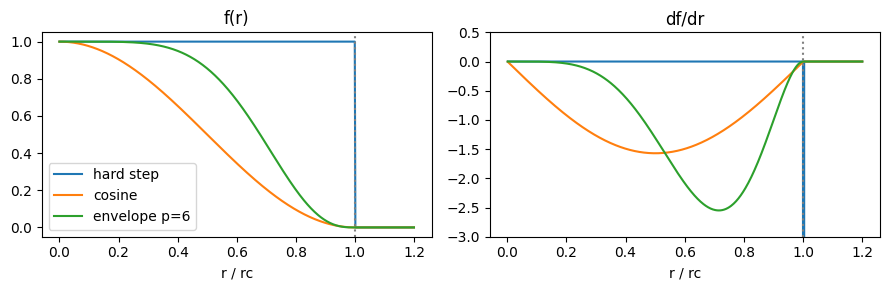

In [3]:
import numpy as np, matplotlib.pyplot as plt

rc = 1.0
r = np.linspace(0, 1.2, 600)
x = np.minimum(r / rc, 1)
hard   = (r < rc).astype(float)
cosine = np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0)
p = 6
env    = np.where(r < rc, 1 - 28 * x**p + 48 * x**(p + 1) - 21 * x**(p + 2), 0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for f, name in [(hard, "hard step"), (cosine, "cosine"), (env, "envelope p=6")]:
    ax[0].plot(r, f, label=name)
    ax[1].plot(r[1:], np.diff(f) / np.diff(r), label=name)
ax[0].set_title("f(r)"); ax[1].set_title("df/dr"); ax[1].set_ylim(-3, 0.5)
for a in ax: a.axvline(rc, color="gray", ls=":"); a.set_xlabel("r / rc")
ax[0].legend(); plt.tight_layout(); plt.show()

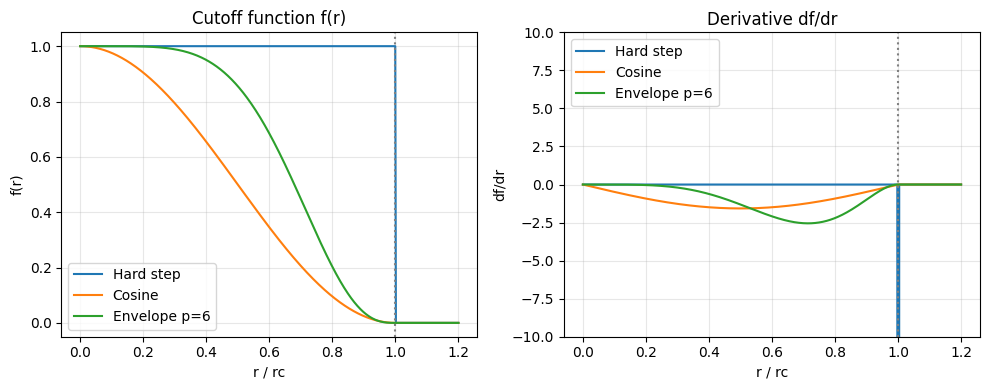

In [4]:

import numpy as np
import matplotlib.pyplot as plt

rc = 1.0
r = np.linspace(0, 1.2, 600)
x = np.minimum(r / rc, 1)

# Hard-step cutoff (discontinuous at rc)
hard = (r < rc).astype(float)

# Cosine cutoff (continuous, with zero slope at rc)
cosine = np.where(
    r < rc,
    0.5 * (np.cos(np.pi * x) + 1),
    0
)

# Smooth envelope cutoff
p = 6
env = np.where(
    r < rc,
    1 - 28 * x**p + 48 * x**(p + 1) - 21 * x**(p + 2),
    0
)

# Plot cutoff functions
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for f, name in [
    (hard, "Hard step"),
    (cosine, "Cosine"),
    (env, "Envelope p=6")
]:
    ax[0].plot(r, f, label=name)

    # Numerical derivative
    derivative = np.gradient(f, r)
    ax[1].plot(r, derivative, label=name)

ax[0].set_title("Cutoff function f(r)")
ax[1].set_title("Derivative df/dr")
ax[1].set_ylim(-10, 10)

for a in ax:
    a.axvline(rc, color="gray", linestyle=":")
    a.set_xlabel("r / rc")
    a.grid(True, alpha=0.3)
    a.legend()

ax[0].set_ylabel("f(r)")
ax[1].set_ylabel("df/dr")

plt.tight_layout()
plt.show()


**Your turn.** The hard step's derivative is a spike (a delta function) at $r_c$. What would that mean for the force on an atom crossing the cutoff during MD?

---
## Exercise 3. A radial fingerprint
$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij})$. Scanning $R_s$ turns the neighbour list of atom $i$ into a smooth curve, essentially a broadened radial distribution function.

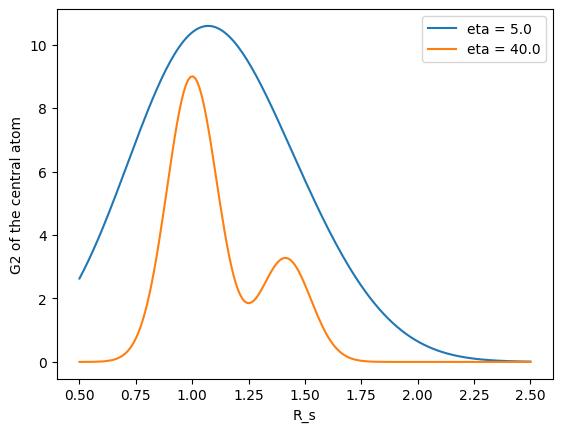

In [5]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

# atom 0 at the centre of a small fcc-like cluster: 12 neighbours at 1.0, 6 at 1.41
nn  = np.array([[1,1,0],[1,-1,0],[-1,1,0],[-1,-1,0],[1,0,1],[1,0,-1],
                [-1,0,1],[-1,0,-1],[0,1,1],[0,1,-1],[0,-1,1],[0,-1,-1]]) / np.sqrt(2)
nnn = np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]]) * np.sqrt(2)
R = np.vstack([[0, 0, 0], nn, nnn])

r0j = np.linalg.norm(R[1:] - R[0], axis=1)
Rs = np.linspace(0.5, 2.5, 200)
for eta in (5.0, 40.0):
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, 3.0)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}")
plt.xlabel("R_s"); plt.ylabel("G2 of the central atom"); plt.legend(); plt.show()

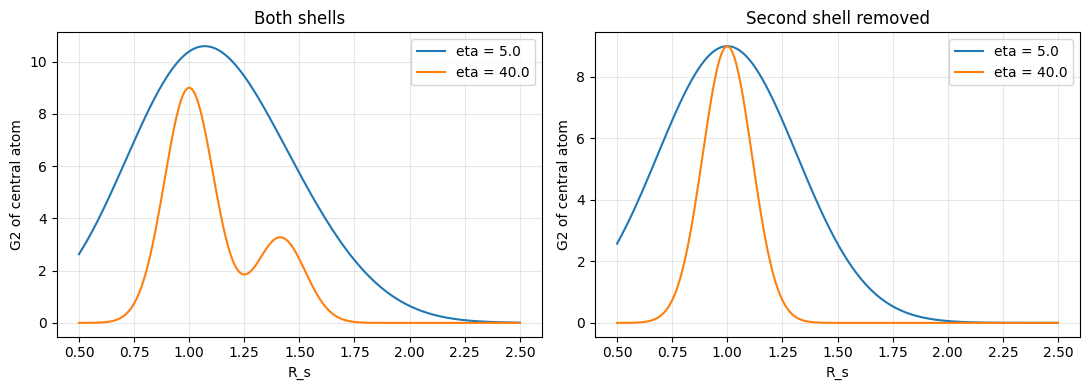

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fc = lambda r, rc: np.where(
    r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0
)

nn = np.array([
    [1,1,0],[1,-1,0],[-1,1,0],[-1,-1,0],
    [1,0,1],[1,0,-1],[-1,0,1],[-1,0,-1],
    [0,1,1],[0,1,-1],[0,-1,1],[0,-1,-1]
]) / np.sqrt(2)

nnn = np.array([
    [1,0,0],[-1,0,0],[0,1,0],
    [0,-1,0],[0,0,1],[0,0,-1]
]) * np.sqrt(2)

R_full = np.vstack([[0, 0, 0], nn, nnn])
R_removed = np.vstack([[0, 0, 0], nn])  # Remove 6 second-shell atoms

Rs = np.linspace(0.5, 2.5, 200)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for a, (R, title) in zip(
    ax,
    [(R_full, "Both shells"), (R_removed, "Second shell removed")]
):
    r0j = np.linalg.norm(R[1:] - R[0], axis=1)

    for eta in (5.0, 40.0):
        G2 = [
            np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, 3.0))
            for s in Rs
        ]
        a.plot(Rs, G2, label=f"eta = {eta}")

    a.set_title(title)
    a.set_xlabel("R_s")
    a.set_ylabel("G2 of central atom")
    a.legend()
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Your turn.** Remove the 6 second-shell atoms. Which peak disappears? With $\eta=5$, can you still tell the two shells apart?

---
## Exercise 4. Angular function versus bond angle
For one triplet, $G^4\propto 2^{1-\zeta}(1+\lambda\cos\theta)^\zeta$ (the radial factors are constant if bond lengths are fixed). Plot the angular factor for several $\zeta$ and both $\lambda$, then recover $\theta$ from the ratio of the two $\lambda$ values: $(1-\cos\theta)/(1+\cos\theta)=\tan^2(\theta/2)$.

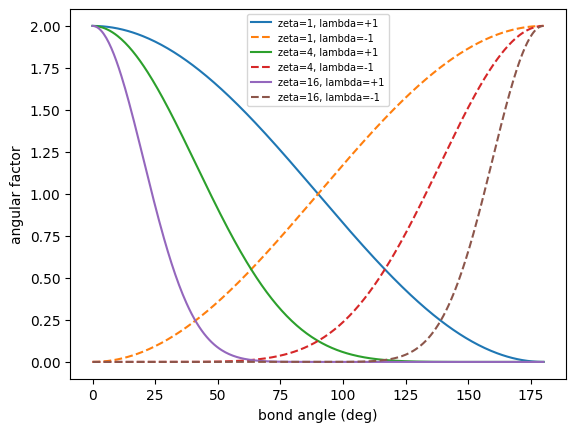

recovered angle: 104.5 deg


In [7]:
import numpy as np, matplotlib.pyplot as plt

theta = np.linspace(0, 180, 361)
c = np.cos(np.deg2rad(theta))
for zeta in (1, 4, 16):
    for lam, st in ((1, "-"), (-1, "--")):
        plt.plot(theta, 2**(1 - zeta) * (1 + lam * c)**zeta, st, label=f"zeta={zeta}, lambda={lam:+d}")
plt.xlabel("bond angle (deg)"); plt.ylabel("angular factor"); plt.legend(fontsize=7); plt.show()

# recover the angle of a single triplet from the two lambda values (zeta = 1)
true_angle = 104.5
cth = np.cos(np.deg2rad(true_angle))
ratio = (1 - cth) / (1 + cth)
print("recovered angle:", round(2 * np.degrees(np.arctan(np.sqrt(ratio))), 2), "deg")

In [ ]:
import numpy as np, matplotlib.pyplot as plt

theta = np.linspace(0, 180, 361)
c = np.cos(np.deg2rad(theta))
for zeta in (1, 16):
    for lam, st in ((1, "-"), (-1, "--")):
        plt.plot(theta, 2**(1 - zeta) * (1 + lam * c)**zeta, st, label=f"zeta={zeta}, lambda={lam:+d}")
plt.xlabel("bond angle (deg)"); plt.ylabel("angular factor"); plt.legend(fontsize=7); plt.show()

# recover the angle of a single triplet from the two lambda values (zeta = 1)
true_angle = 104.5
cth = np.cos(np.deg2rad(true_angle))
ratio = (1 - cth) / (1 + cth)
print("recovered angle:", round(2 * np.degrees(np.arctan(np.sqrt(ratio))), 2), "deg")

In [8]:
import numpy as np

angles = [104.5, 109.5]

for zeta in (1, 4, 16):
    for lam in (1, -1):
        values = [
            2**(1-zeta) *
            (1 + lam*np.cos(np.deg2rad(theta)))**zeta
            for theta in angles
        ]

        relative_diff = (
            abs(values[0] - values[1]) /
            max(abs(values[0]), abs(values[1]))
            * 100
        )

        print(
            f"zeta={zeta:2}, lambda={lam:+d}, "
            f"f1={values[0]:.6f}, f2={values[1]:.6f}, "
            f"relative difference={relative_diff:.2f}%"
        )

zeta= 1, lambda=+1, f1=0.749620, f2=0.666193, relative difference=11.13%
zeta= 1, lambda=-1, f1=1.250380, f2=1.333807, relative difference=6.25%
zeta= 4, lambda=+1, f1=0.039471, f2=0.024621, relative difference=37.62%
zeta= 4, lambda=-1, f1=0.305547, f2=0.395623, relative difference=22.77%
zeta=16, lambda=+1, f1=0.000000, f2=0.000000, relative difference=84.86%
zeta=16, lambda=-1, f1=0.001089, f2=0.003062, relative difference=64.42%


**Your turn.** Which $\zeta$ would you use to distinguish $100^\circ$ from $110^\circ$? Compute $(1-\cos\theta)^\zeta$ at both angles for $\zeta=1$ and $\zeta=16$ and compare the relative difference.